# Audible Insights: Exploratory Data Analysis

This notebook answers every question in the project brief (5 easy, 4 medium, 3 scenario) plus my own analysis.
All numbers come from `data/processed/books_clean.csv` (built by `pipeline.py`) and the models in `models/`
(built by `train.py`). The analysis functions live in `src/eda.py`, so the app and the report use exactly the same
logic.

**The data in one paragraph.** The two files merge into **6,056 unique books**. 5,479 are rated; the rest have
`-1` (not yet rated). Only **2,298** have a real description: about 2,000 of the raw descriptions are scraping
failures (CAPTCHA pages, "rush hour" error pages, checkout boilerplate) or award one-liners. Only **2,059** have
Audible genre ranks. So genre-level answers rest on roughly a third of the catalogue, while rating and author answers
use all rated books. Prices are in ₹ (Audible India).

In [1]:
%matplotlib inline
import sys, json, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")
import joblib, numpy as np, pandas as pd
from IPython.display import display, Image
import config
from src import eda

pd.set_option("display.max_colwidth", 70)
pd.set_option("display.width", 200)
books = eda.load_books()
metrics, cluster_summary = eda.load_metrics()
rec = joblib.load(config.RECOMMENDER_ARTIFACTS).recommender
cleaning = json.loads(config.CLEANING_REPORT.read_text())
print(f"{len(books):,} books | rated {books['is_rated'].sum():,} | with description {books['has_description'].sum():,} "
      f"| listed genre {(books['genre_source']=='listed').sum():,} | inferred genre {(books['genre_source']=='inferred').sum():,}")

6,056 books | rated 5,479 | with description 2,298 | listed genre 2,059 | inferred genre 218


## 0. Data quality: what cleaning found

In [2]:
display(pd.Series(cleaning["missing_raw"], name="raw issues").to_frame())
display(pd.DataFrame({k: cleaning[k] for k in ["dedup_catalog", "dedup_advanced"]}))
display(pd.Series(cleaning["merge"], name="merge").to_frame())
display(pd.Series(cleaning["final_coverage"], name="final coverage").to_frame())

,raw issues
catalog_unrated_(rating_-1),631
catalog_price_missing,3
advanced_unrated_(rating_-1),421
advanced_description_missing,6
advanced_description_junk,2022
advanced_description_award_blurb_only,94
advanced_listening_time_missing,2271
advanced_ranks_and_genre_missing,2268


,dedup_catalog,dedup_advanced
rows_in,6368,4464
exact_duplicates,929,234
same_book_duplicates,43,223
rows_out,5396,4007


,merge
books,6056
in_both_files,3347
only_catalog,2049
only_advanced,660


,final coverage
rated,5479
with_description,2298
with_listed_genre,2059
with_listening_time,2095
price_missing,1
price_decimal_shift_corrected,132
fine_genres,876


**What this means.** 929 rows of the basic catalog are exact duplicates. Over half of the advanced file's
descriptions are not descriptions at all, and the same scrape failures cost those rows their genre and listening time.
These were handled, not hidden: junk text becomes *missing*; the 876 fine genres are mapped to 17 broad genres; and a
text classifier infers the broad genre for books that have a description but no genre (cross-validated accuracy
52% over 17 classes, 70% on the confident predictions it keeps). Books that are still unknown are labelled **Unknown**,
never guessed.

**Prices.** 132 prices are 10× too high, from a dropped decimal point ("A Game of Thrones" at ₹18,149). The evidence:
those books are as long as the rest (median 8.4 h vs 8.2 h) but cost 14× more per hour. Divided by 10 they cost
₹128 per hour, in line with the catalogue (IQR ₹66–124). They were divided by 10 and flagged `price_corrected`.

## Easy questions
### Q1. What are the most popular genres in the dataset?

,books,total_reviews,median_reviews,avg_rating,share_of_reviews
primary_genre,,,,,
Literature & Fiction,301,"508,037",411,4.32,18.2%
Business & Careers,277,"184,276",185,4.50,6.6%
Personal Development,257,"262,364",189,4.49,9.4%
Religion & Spirituality,216,"148,460",185,4.56,5.3%
Children & Teens,180,"368,911",479,4.59,13.2%
"Psychology, Philosophy & Society",157,"149,352",265,4.44,5.4%
Science & Technology,119,"78,721",275,4.46,2.8%
"Mystery, Thriller & Horror",115,"310,503",889,4.42,11.1%
Money & Finance,110,"99,709",214,4.39,3.6%


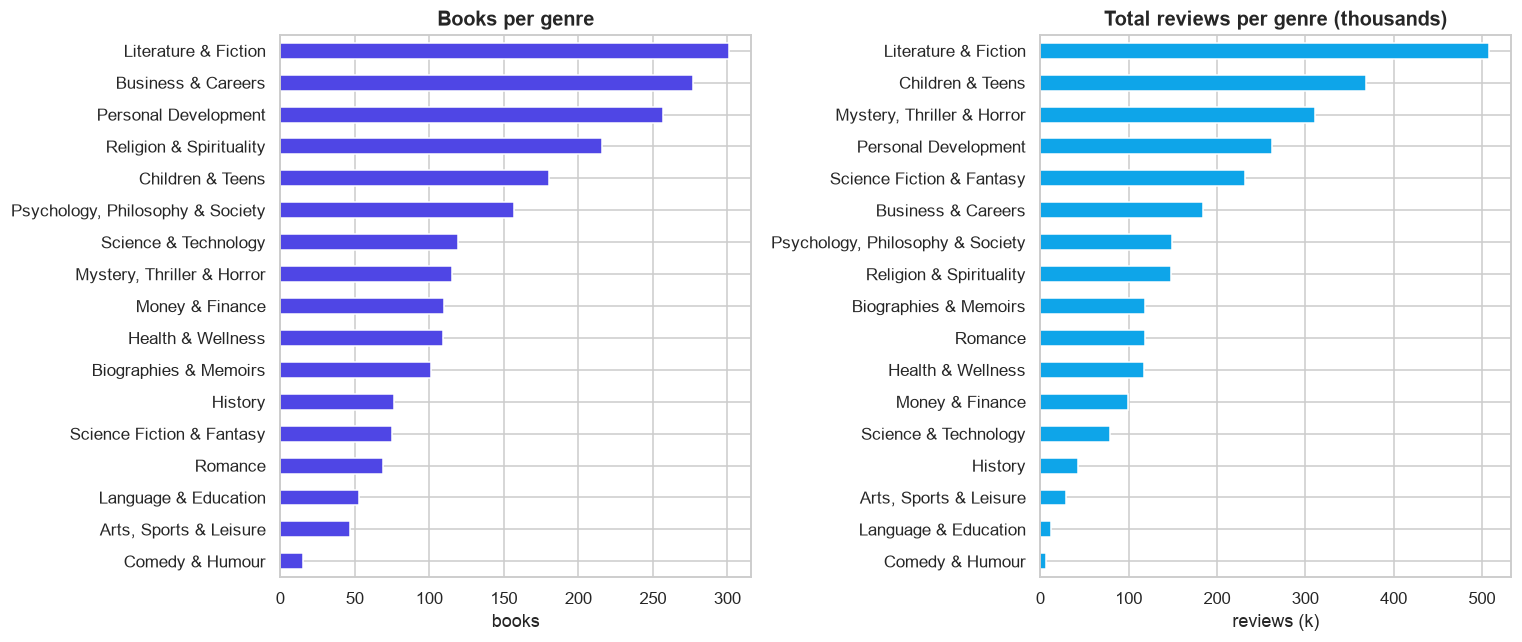

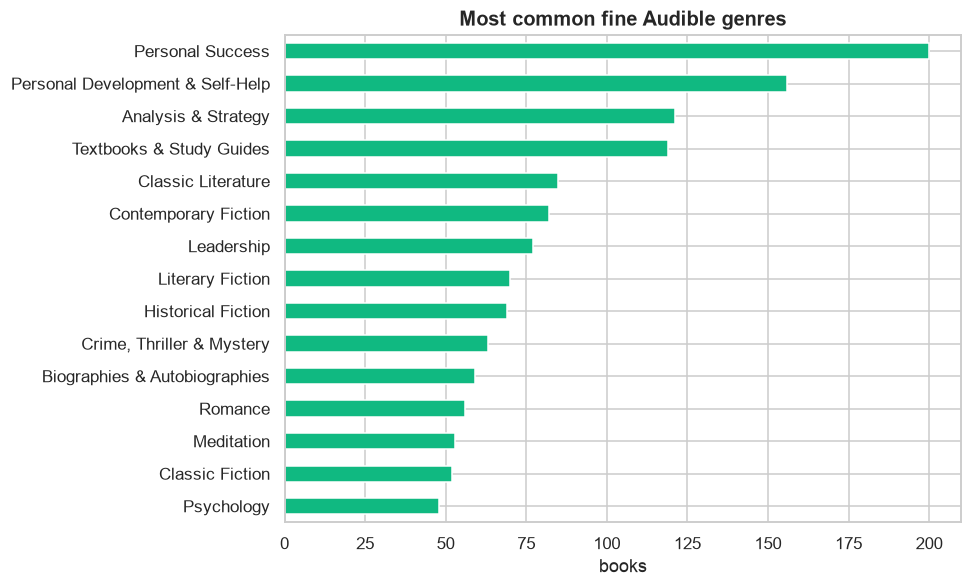

In [3]:
g = eda.q1_popular_genres(books)
display(g.style.format({"total_reviews": "{:,.0f}", "avg_rating": "{:.2f}", "share_of_reviews": "{:.1%}",
                        "median_reviews": "{:,.0f}"}))
eda.chart_genres(books); eda.chart_fine_genres(books);

**Answer.** It depends on what "popular" means:
- **By number of titles:** Literature & Fiction (301 books), Business & Careers (277) and Personal Development (257)
  lead. The catalogue leans heavily towards non-fiction self-improvement.
- **By listeners (total reviews):** Literature & Fiction (18% of all reviews), **Children & Teens (13%)** and
  **Mystery, Thriller & Horror (11%)**. Business is only 6% of reviews despite being the second-largest shelf.
- **By engagement per title:** Science Fiction & Fantasy has the highest median reviews per book (1,412), about 8×
  Business (183). Thrillers come second (889). These genres have fewer titles but much bigger audiences per title.

The most common *fine* genres are Personal Success, Personal Development & Self-Help and Analysis & Strategy.

### Q2. Which authors have the highest-rated books?

,books,avg_rating,avg_weighted_rating,total_reviews
author,,,,
Tracey West,3,4.87,4.83,"1,633"
Tui T. Sutherland,9,4.86,4.84,"10,414"
Joyce Meyer,3,4.80,4.69,"1,178"
Bill Johnson,3,4.80,4.74,969
Watchman Nee,3,4.80,4.73,819
Norman Bridwell,5,4.78,4.69,"1,209"
Julia Donaldson,13,4.77,4.75,"30,443"
Chris Colfer,3,4.77,4.75,"3,550"
John Flanagan,3,4.77,4.74,"2,211"


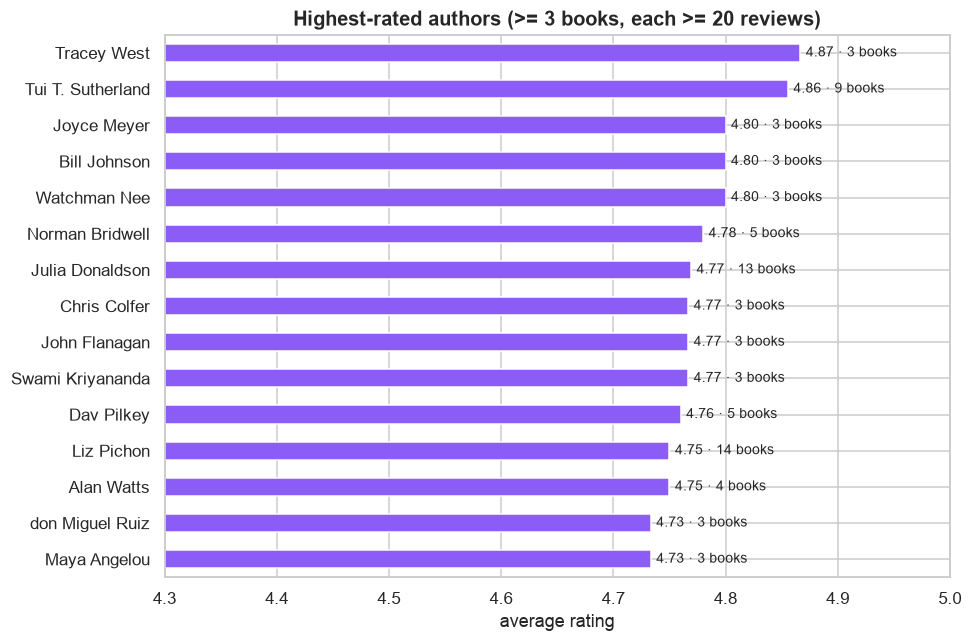

In [4]:
a = eda.q2_top_authors(books)
display(a.head(15).style.format({"avg_rating": "{:.2f}", "avg_weighted_rating": "{:.2f}", "total_reviews": "{:,.0f}"}))
eda.chart_top_authors(books);

**Answer.** I only counted authors with at least 3 rated books, each with at least 20 reviews, so one lucky 5-star book
can't top the list. **Tracey West (4.87)**, **Tui T. Sutherland (4.86 over 9 books, 10k reviews)**, Joyce Meyer,
Bill Johnson and Watchman Nee (4.80) lead. Julia Donaldson (13 books, 30k reviews, 4.77) is the most remarkable:
consistently top-rated at scale.

Children's authors (Sutherland, Bridwell, Donaldson, Colfer, Pilkey, Pichon) and Christian/spiritual writers dominate
the top. Both genres rate above the catalogue average (4.59 and 4.56 vs 4.46).

### Q3. What is the average rating distribution across books?

{'rated_books': 5479, 'unrated_books': 577, 'mean': 4.457, 'median': 4.5, 'std': 0.351, 'skew': -3.088, 'share_4_5_plus': 0.607, 'share_below_4': 0.056}


,books
rating,
< 3.0,36
3.0-3.4,60
3.5-3.9,212
4.0-4.4,1844
4.5-5.0,3327


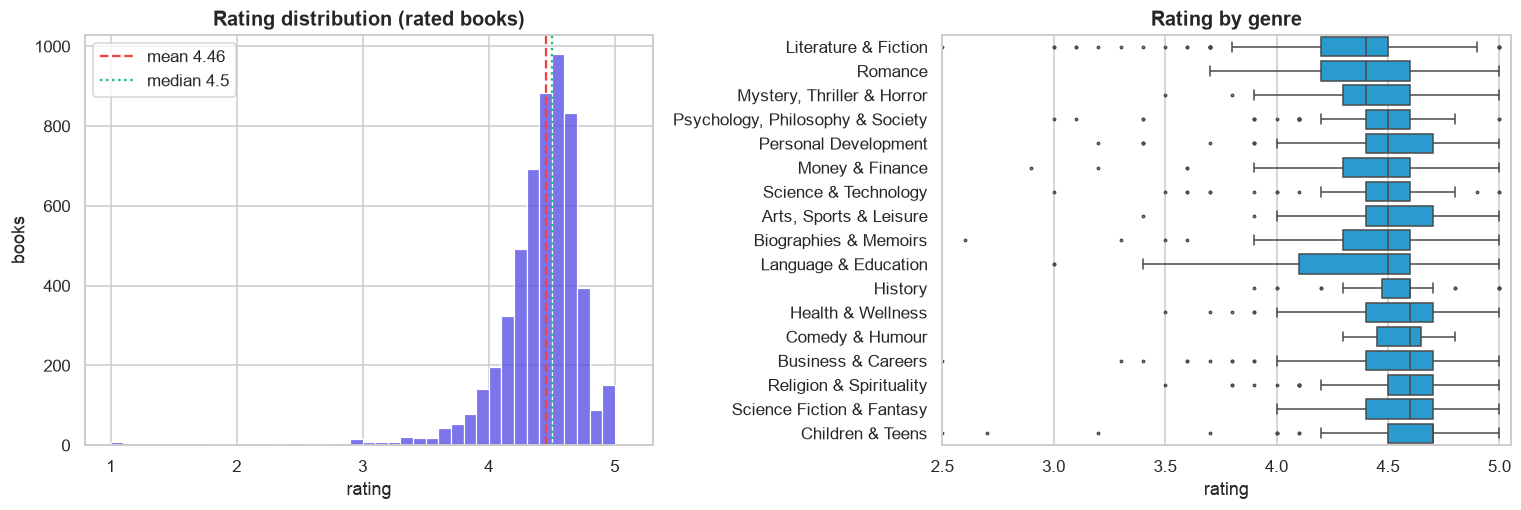

In [5]:
d = eda.q3_rating_distribution(books)
print({k: round(float(v), 3) if not isinstance(v, (pd.Series, int)) else v for k, v in d.items() if k != "bands"})
display(d["bands"].to_frame("books"))
eda.chart_rating_distribution(books);

**Answer.** Ratings are crowded at the top. The mean is **4.46**, the median **4.5**, and the standard deviation only
0.35. **61% of rated books score 4.5 or more**, and only 5.6% fall below 4.0 (skew −3.1). A 4.3 is therefore below
average here, which is why the recommenders use a *weighted* rating (shrunk towards the mean when reviews are few)
rather than the raw stars.

By genre, Children & Teens, Religion & Spirituality, Comedy and Science Fiction & Fantasy rate highest. Literature &
Fiction (4.32) and Language & Education (4.34) rate lowest.

### Q4. Are there trends in publication years for popular books?

{'publication_date_column': False, 'descriptions_stating_a_publication_year': 17, 'titles_containing_a_year': 40}


,avg_rating,median_reviews,books
rank_band,,,
1-100,4.493056,3196.5,72
101-500,4.456540,773.0,237
501-1k,4.491518,428.5,224
1k-2.5k,4.448346,436.0,544
2.5k-5k,4.478838,239.0,671
5k-10k,4.447368,39.0,19
25k+,4.415789,69.0,19


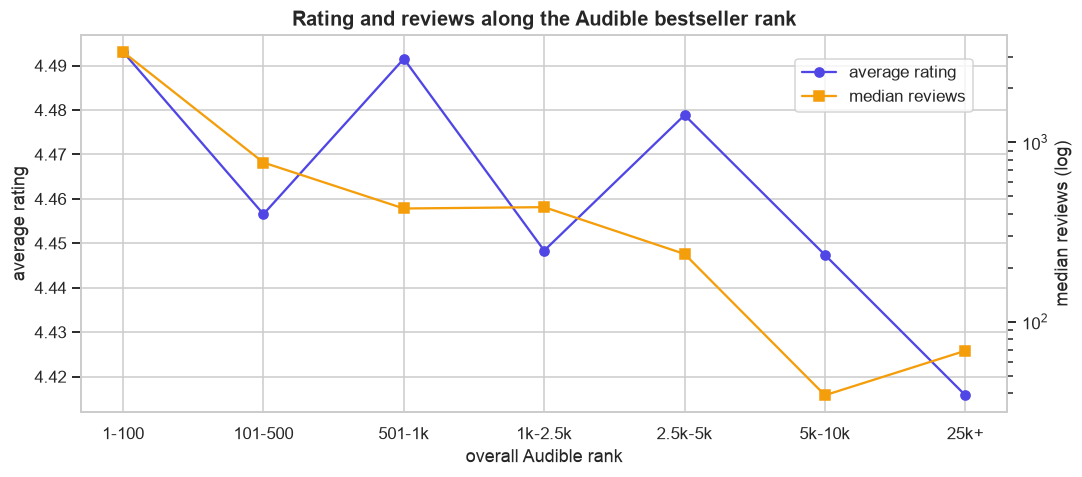

In [6]:
print(eda.q4_publication_years(books))
display(eda.chart_popularity_curve(books))

**Answer: this cannot be answered from the provided data, and I am not going to invent it.** Neither CSV has a
publication date. Only 17 descriptions state one ("first published in 1936") and 40 titles contain a year, which is
far too few for a trend.

What the data *does* have is the overall Audible bestseller rank, so the line chart above is the closest honest
substitute. Moving down the rank, median reviews fall steeply (3,197 for the top 100 → 239 at rank 2.5k–5k), while
average rating barely moves (4.42–4.49). **Popularity and quality are almost independent in this catalogue.** To
answer the original question, publication years would have to be joined in from an external source such as the
Open Library or Google Books API (matched on title + author). That is listed as future work.

### Q5. How do ratings vary between books with different review counts?

,books,avg_rating,std,share_5_star,share_below_4
review_band,,,,,
1-9,411,4.26,0.86,32.8%,24.6%
10-49,761,4.34,0.39,1.8%,13.5%
50-199,1340,4.44,0.25,0.1%,4.0%
200-999,1853,4.51,0.22,0.1%,1.9%
1k-5k,906,4.53,0.20,0.0%,1.5%
5k+,208,4.52,0.18,0.0%,1.0%


{'spearman_rho': np.float64(0.16209704208077855), 'p_value': np.float64(1.42002876181663e-33)}


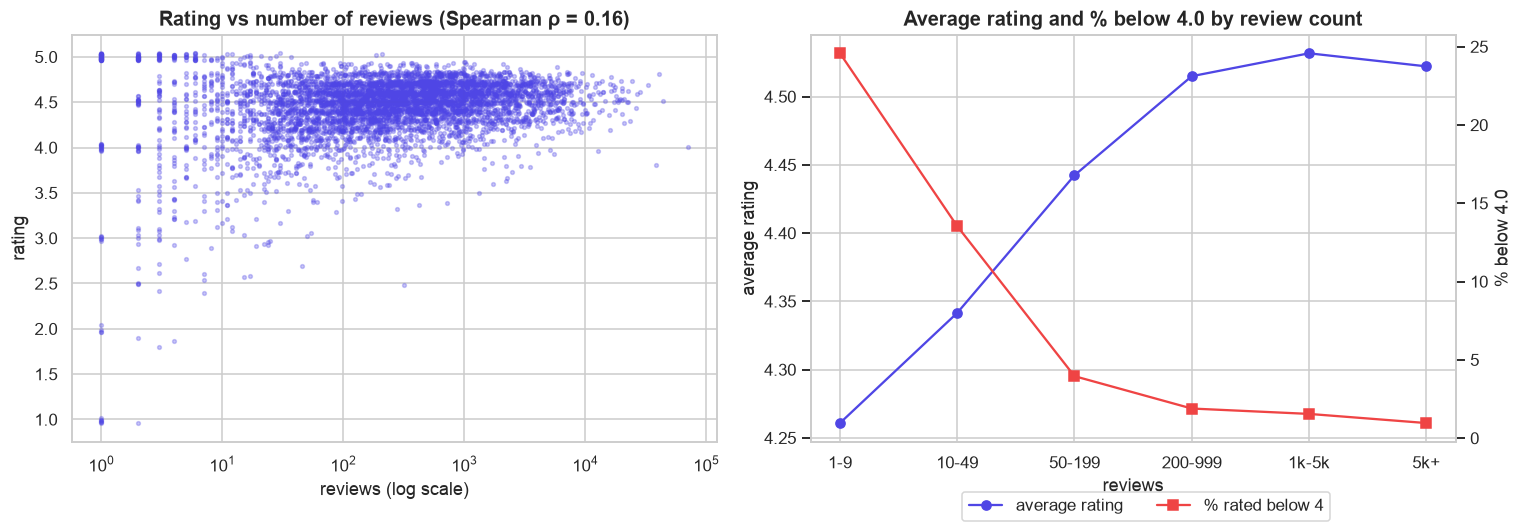

In [7]:
t, s = eda.q5_ratings_vs_reviews(books)
display(t.style.format({"avg_rating": "{:.2f}", "std": "{:.2f}", "share_5_star": "{:.1%}", "share_below_4": "{:.1%}"}))
print(s)
eda.chart_ratings_vs_reviews(books);

**Answer.** Books with few reviews have far more extreme ratings, in both directions:
- With 1–9 reviews, **33% are perfect 5.0s and 25% are below 4.0** (std 0.86).
- From 200 reviews up, almost nothing is 5.0 or below 4.0 (std ≈ 0.2).

The average rises with review count, from 4.26 to about 4.52, then flattens after 1,000 reviews. The overall
correlation is weak but real (Spearman ρ = 0.16, p < 10⁻³²).

Two practical consequences. A raw 5.0 is mostly a small-sample artefact. And widely read books are rarely bad. This is
exactly why the system ranks by Bayesian weighted rating (m = 50 reviews).

## Medium questions
### Q6. Which books are frequently clustered together based on descriptions?

KMeans k = 16 (chosen by silhouette), fitted on 2,059 books with listed genres
how books got their cluster: {'title': 3520, 'fitted': 2059, 'description': 477}


,cluster,name,books,fitted,avg_rating,top_terms,examples
1,1,"Personal Development · life, success, people",633,237,4.464,"life, success, people, positive, mind, happiness",How to Win Friends and Influence People · The Subtle Art of Not Gi...
7,7,"Business & Careers · business, leadership, management",530,242,4.487,"business, leadership, management, leaders, hbr, thinking","Thinking, Fast and Slow · The Art of War · Daring Greatly: How the..."
0,0,"Mystery, Thriller & Horror · murder, thriller, poirot",508,106,4.431,"murder, thriller, poirot, killer, secret, mystery",The Girl on the Train · Inferno · The Girl in the Spider's Web: Co...
6,6,"Religion & Spirituality · spiritual, god, meditation",508,183,4.544,"spiritual, god, meditation, wisdom, power, teachings",The Power of Your Subconscious Mind · The Four Agreements · The Un...
2,2,"Literature & Fiction · novel, love, story",470,280,4.350,"novel, love, story, stories, short, tale",The Nightingale · The Alchemist: A Fable About Following Your Drea...
4,4,"Children & Teens · stories, kid, diary",441,154,4.543,"stories, kid, diary, wimpy, wimpy kid, diary wimpy","The Fault in Our Stars · Mockingjay: The Hunger Games, Book 3 · Wo..."
11,11,"Science Fiction & Fantasy · dark, doctor, blood",385,70,4.498,"dark, doctor, blood, sun, humanity, trilogy","The Martian · Outlander: Outlander, Book 1 · Ready Player One"
12,12,"Science & Technology · physics, nature, universe",351,109,4.442,"physics, nature, universe, theory, science, human",Astrophysics for People in a Hurry · A Brief History of Time: From...
9,9,"Romance · love, dirty, love tinder",341,62,4.391,"love, dirty, love tinder, tinder, girl, novel",Me Before You · Fifty Shades Freed: Book Three of the Fifty Shades...
3,3,"Health & Wellness · body, weight, health",335,92,4.471,"body, weight, health, mind, weight loss, loss","Wild · When Breath Becomes Air · The Body Keeps the Score: Mind, B..."


,eps,clusters,noise_share,largest_cluster_share,silhouette_clustered_only,agreement_with_kmeans_ari
0,0.3,10,0.9704,0.0044,0.8000,-0.0000
1,0.4,26,0.8873,0.0194,0.5999,-0.0008
2,0.5,47,0.7237,0.0369,0.3916,0.0191
3,0.6,56,0.3706,0.0894,0.2377,0.2144
4,0.7,23,0.0835,0.1243,0.2674,0.8393
5,0.8,18,0.0087,0.1355,0.3355,0.9848
6,0.9,16,0.0000,0.1360,0.3318,0.9825
7,1.0,5,0.0000,0.8660,0.0719,0.0544


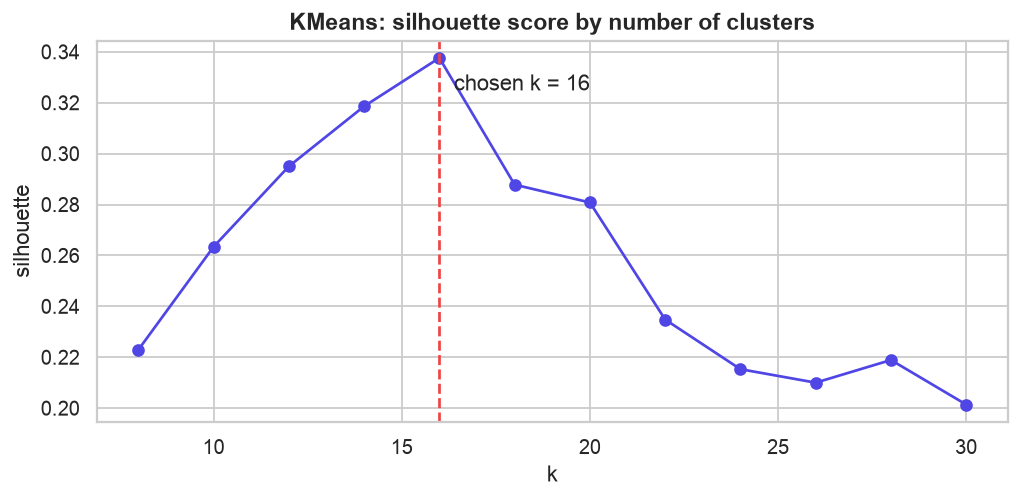

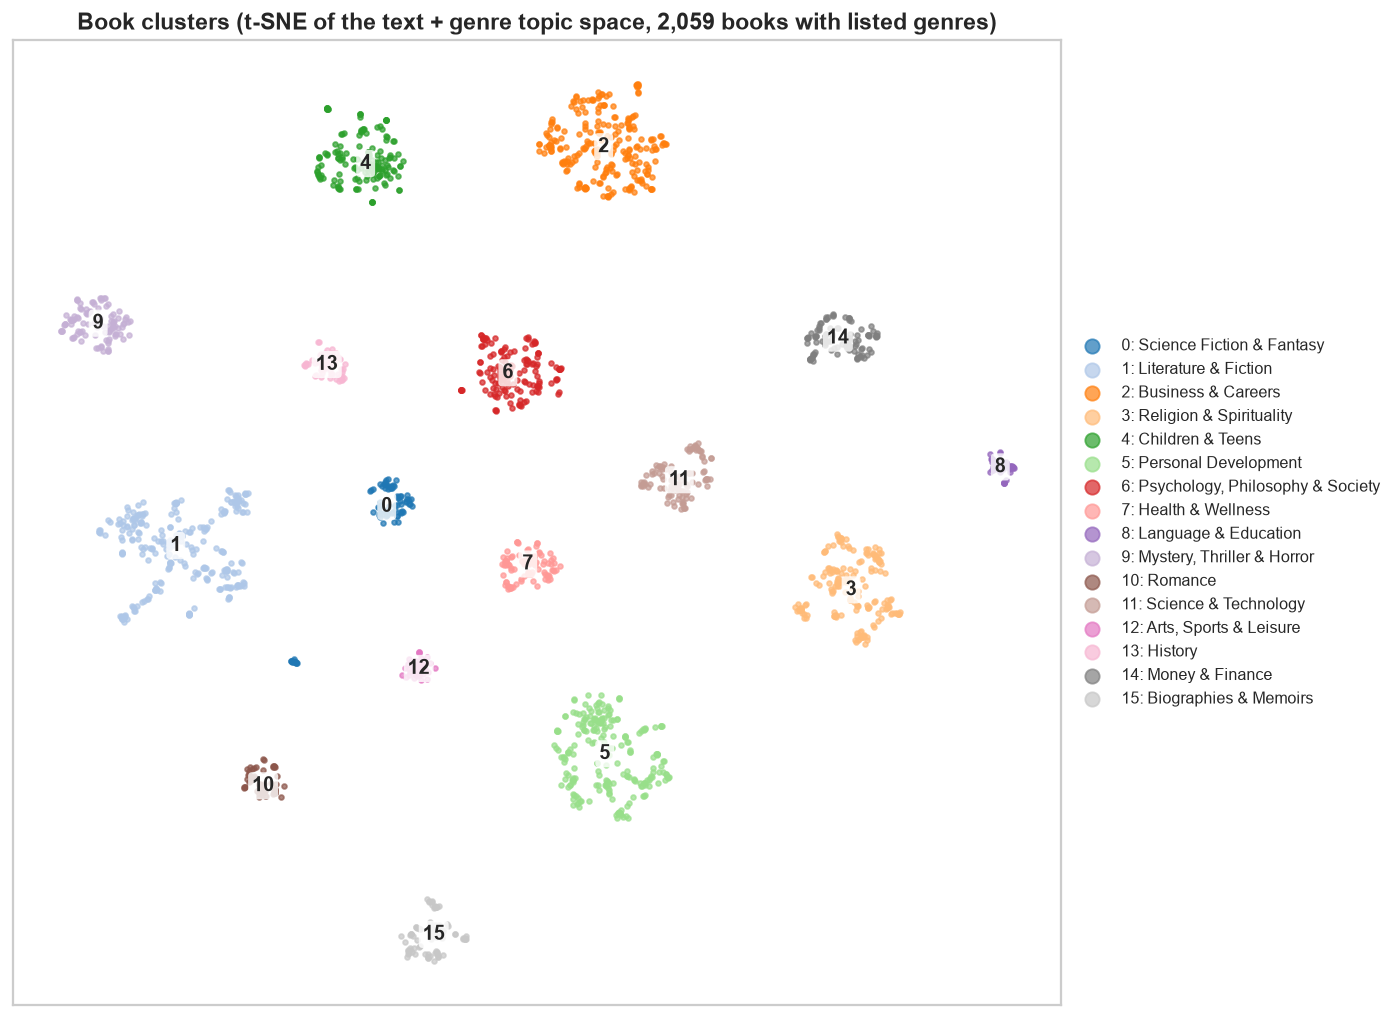

In [8]:
c = metrics["clustering"]
print(f"KMeans k = {c['k']} (chosen by silhouette), fitted on {c['fitted_on_books']:,} books with listed genres")
print("how books got their cluster:", c["assigned_by"])
display(eda.q6_cluster_table(cluster_summary))
display(pd.DataFrame(c["dbscan"]))
for f in ["silhouette", "clusters_map"]:
    display(Image(filename=str(config.FIGURES_DIR / f"{f}.png")))

In [9]:
pairs = eda.q6_most_similar_pairs(books)
display(pairs.style.format({"similarity": "{:.3f}"}))

,book_a,book_b,similarity,same_cluster
0,The Blue Jackal,Rangeela Geedad,0.843,True
1,Good Omens: The BBC Radio 4 dramatisation,Neverwhere: A BBC Radio Full-Cast Dramatisation,0.825,True
2,2666,The Inheritance of Loss,0.776,True
3,The Old Man and the Sea: CliffsNotes,The Kite Runner: CliffsNotes,0.776,True
4,Forge Your Future,Aapka Bhavishya Aapke Haath Mein [Forge Your Future],0.730,True
5,Good Night Stories for Rebel Girls,Goodnight Stories for Rebel Girls 2: 100 More Stories of Extraordinary Women,0.728,True
6,A Squash and a Squeeze,The Smartest Giant in Town,0.702,True
7,टिंडर टैक्सी - एक कामुक लघुकथा,द निम्फ़ एंड द फ़ॉन्स - एक कामुक लघुकथा,0.701,True
8,द निम्फ़ एंड द फ़ॉन्स - एक कामुक लघुकथा,वॉयर - एक कामुक लघुकथा,0.683,True
9,Gardens of the Moon: The Malazan Book of the Fallen 1,House of Chains: The Malazan Book of the Fallen 4,0.679,True


**Answer.** TF-IDF on titles and descriptions (with a light genre signal), reduced to 150 SVD "topic" dimensions,
falls into **16 clear clusters** (silhouette peaks at k = 16, 0.339). Each one reads as a recognisable shelf:
- **Mystery & Thriller:** Poirot, *The Girl on the Train*, Jack Reacher.
- **Money & Finance:** *Think and Grow Rich*, *Rich Dad Poor Dad*, *The Intelligent Investor*.
- **Science & Technology:** *A Brief History of Time*, *Astrophysics for People in a Hurry*.
- **Spirituality:** *The Power of Your Subconscious Mind*, *The Four Agreements*.

**DBSCAN as a cross-check.** DBSCAN is very sensitive to its radius (eps). At eps 0.3 it calls 97% of books noise; at
1.0 one cluster swallows 87%. At eps 0.8–0.9 it finds 16–18 clusters with almost no noise, and they **agree with
KMeans at an adjusted Rand index of 0.98**. Two different algorithms find the same structure, so the clusters are real
rather than an artefact of KMeans. KMeans is kept because it gives every book a cluster, and its centroids can place
the 3,997 books without a listed genre.

**Most similar pairs by description alone** (different authors, same cluster):
- the same story in two languages (*The Blue Jackal* / *Rangeela Geedad*);
- BBC radio dramatisations (*Good Omens* / *Neverwhere*);
- CliffsNotes study guides;
- *Good Night Stories for Rebel Girls* volumes 1 and 2;
- consecutive Malazan novels.

### Q7. How does genre similarity affect book recommendations?

In [10]:
cmp = pd.DataFrame(metrics["model_comparison"])
display(cmp.style.format({c: "{:.3f}" for c in cmp.columns if "@" in c or c in ("avg_rating_of_recs", "catalogue_coverage")}))

,model,precision@10,recall@10,ndcg@10,strict_precision@10,avg_rating_of_recs,catalogue_coverage,queries,uses_fine_genres
0,Random,0.042,0.005,0.042,0.006,4.459,0.950,596,False
1,Most popular (weighted rating),0.020,0.005,0.021,0.001,4.890,0.005,596,False
2,Content-based (genre-blind),0.191,0.046,0.214,0.052,4.458,0.891,596,False
3,Clustering-based (genre-blind),0.110,0.019,0.107,0.013,4.766,0.086,596,False
4,Hybrid (genre-blind),0.218,0.051,0.240,0.053,4.490,0.876,596,False
5,Content-based (full features),0.859,0.249,0.905,0.385,4.459,0.856,596,True
6,Clustering-based (full features),0.206,0.043,0.204,0.034,4.766,0.085,596,True
7,Hybrid (full features),0.857,0.248,0.904,0.385,4.493,0.851,596,True


**Answer.** Genre similarity is the strongest single driver of recommendation quality. Here a recommendation counts as
*relevant* when it shares at least one of the query's fine Audible genres; precision is measured over the top 10,
across 596 test books.
- **Description text alone** (genre-blind) gets **19% precision@10**, about 5× random (4%). So description NLP alone
  recovers genre-mates.
- **Adding the broad genre** (17 classes) almost doubles precision, from 0.19 to **0.35** (see Q9).
- **Using the fine genres directly** reaches 0.86. That number is optimistic, because the fine genres are also what
  defines "relevant"; treat it as an upper bound, not a fair score.
- **The cluster-based model** recommends the best-rated books in the query's cluster. Its precision is lower (0.11
  genre-blind) and it covers only 9% of the catalogue. But its recommendations rate highest (4.77 average): it trades
  personalisation for safe, popular picks.
- **The hybrid** (content + same cluster + quality, weights tuned on separate validation queries) beats pure content
  in the genre-blind setting (0.218 vs 0.191 precision, 0.240 vs 0.214 nDCG) and also recommends better-rated books.

### Q8. What is the effect of author popularity on book ratings?

,books,avg_rating,share_below_4
author_popularity,,,
1-99,257,4.415,8.2%
100-999,779,4.424,6.3%
1k-10k,1228,4.484,3.7%
10k+,360,4.526,2.8%


{'spearman_rho': np.float64(0.09470349928854817), 'p_value': np.float64(1.1750423567756125e-06), 'books_by_multi_book_authors': 2624}


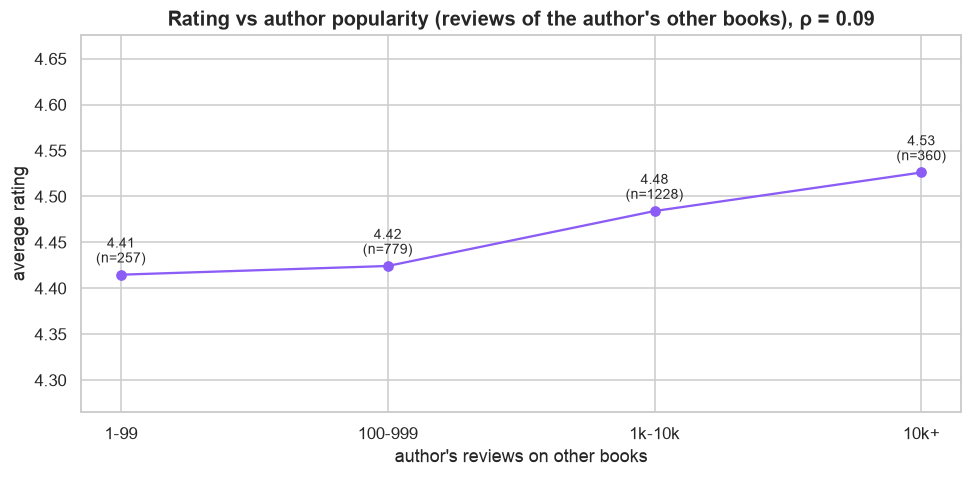

In [11]:
t, s = eda.q8_author_popularity(books)
display(t.style.format({"avg_rating": "{:.3f}", "share_below_4": "{:.1%}"}))
print(s)
eda.chart_author_popularity(books);

**Answer.** Here, author popularity means the reviews on the author's *other* books, so a single blockbuster is not
compared with itself. There's a small, consistent positive effect:
- Books by authors whose other work has 10k+ reviews average **4.53**, against **4.42** for authors with under 100.
- The share of books rated below 4.0 drops from 8.2% to 2.8%.

The correlation is weak (ρ = 0.09, p ≈ 10⁻⁶): **an established author is a safer bet, not a guarantee.** This is why
the author is a small feature block (weight 0.3) in the content model, and why "Author mean" is a strong rating
predictor (Q9, RMSE table).

### Q9. Which combination of features provides the most accurate recommendations?

,features,precision@10,recall@10,ndcg@10,strict_precision@10,avg_rating_of_recs,catalogue_coverage,queries,uses_fine_genres
0,text (title + description),0.191,0.046,0.214,0.052,4.458,0.891,596,False
1,text + author,0.210,0.052,0.239,0.059,4.457,0.892,596,False
2,text + broad genre,0.350,0.077,0.364,0.088,4.480,0.801,596,False
3,text + broad genre + author,0.360,0.082,0.382,0.092,4.477,0.816,596,False
4,"all, incl. fine genres",0.859,0.249,0.905,0.385,4.459,0.856,596,True


,model,rmse,mae,test_books,train_books
0,Global mean (baseline),0.2743,0.2021,1045,4176
1,Genre mean,0.2694,0.1966,1045,4176
2,Author mean,0.2542,0.1861,1045,4176
3,k-NN content (text only),0.2686,0.1968,1045,4176
4,k-NN content (all features),0.2571,0.1864,1045,4176
5,Hybrid (k-NN + author mean),0.2512,0.1830,1045,4176


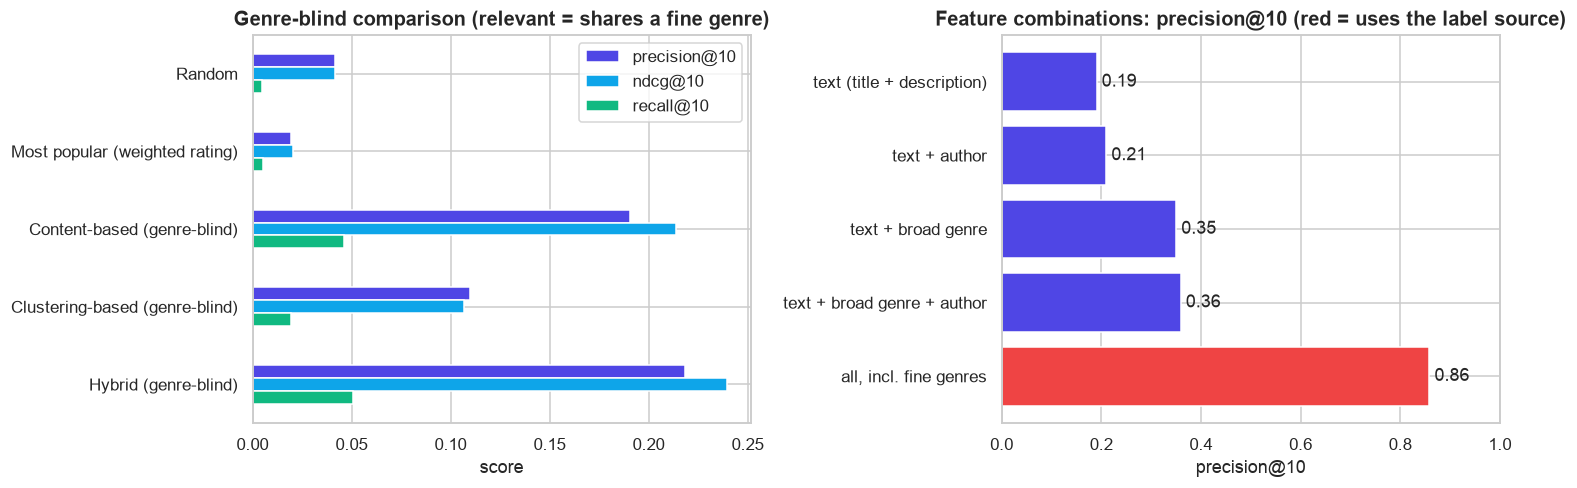

In [12]:
abl = pd.DataFrame(metrics["feature_ablation"])
display(abl.style.format({c: "{:.3f}" for c in abl.columns if "@" in c or c in ("avg_rating_of_recs", "catalogue_coverage")}))
rmse = pd.DataFrame(metrics["rating_prediction"])
display(rmse.style.format({"rmse": "{:.4f}", "mae": "{:.4f}"}))
eda.chart_model_comparison(metrics);

**Answer.** Feature blocks were added one at a time to the content-based model:

| features | precision@10 | nDCG@10 |
|---|---|---|
| text (title + description) | 0.191 | 0.214 |
| + author | 0.210 | 0.239 |
| + broad genre | 0.351 | 0.364 |
| **+ broad genre + author** | **0.360** | **0.382** |
| all, incl. fine genres (upper bound) | 0.859 | 0.905 |

**Text + broad genre + author is the best fair combination.** Every block adds something, and the genre block adds by
far the most. The production model also uses the fine genres, because they are real information about every book that
has them.

For **rating prediction** (RMSE, 1,045 held-out books), averaging the k-NN content prediction with the author's mean
rating does best: **RMSE 0.251 vs 0.274** for always predicting the mean (−8%). That gain is small because ratings
barely vary (std 0.35). Ratings are a weak signal in this data, so the system ranks by similarity first and uses
quality as a tie-breaker.

## Scenario questions
### S1. A new user likes science fiction. Which top 5 books should be recommended?

In [13]:
top, more = eda.scenario_scifi(books, rec)
cols = ["title", "author", "rating", "num_reviews", "weighted_rating"]
display(top[cols].style.format({"weighted_rating": "{:.2f}"}))
print("If they want five more, the hybrid model seeded with the top sci-fi titles suggests:")
display(more[cols].style.format({"weighted_rating": "{:.2f}"}))

,title,author,rating,num_reviews,weighted_rating
388,Morning Star: Book III of the Red Rising Trilogy,Pierce Brown,4.800000,3016,4.79
3133,"So Long, Lollipops: The Free Until The End of the World Novella",Sarah Lyons Fleming,4.800000,174,4.72
4,The Martian,Andy Weir,4.700000,33293,4.70
356,Jurassic Park: A Novel,Michael Crichton,4.700000,3259,4.70
510,Thrawn (Star Wars),Timothy Zahn,4.700000,2328,4.69


If they want five more, the hybrid model seeded with the top sci-fi titles suggests:


,title,author,rating,num_reviews,weighted_rating
188,Red Rising,Pierce Brown,4.600000,5271,4.60
1627,The Restaurant at the End of the Universe,Douglas Adams,4.600000,597,4.59
1307,Blade Runner: Originally published as Do Androids Dream of Electric Sheep?,Philip K. Dick,4.600000,824,4.59
827,Hyperion,Dan Simmons,4.400000,1410,4.40
1249,Anthem,Ayn Rand,4.300000,880,4.31


**Answer.** A new user has no history (cold start), so I take books whose Audible genres include "Science Fiction"
(children's titles excluded) and rank them by weighted rating:
1. *Morning Star* (Pierce Brown)
2. *So Long, Lollipops* (Sarah Lyons Fleming)
3. *The Martian* (Andy Weir)
4. *Jurassic Park* (Michael Crichton)
5. *Thrawn* (Timothy Zahn)

All rate 4.7–4.8, and *The Martian* has 33k reviews. Once they've started, the hybrid model suggests *Red Rising*,
*The Restaurant at the End of the Universe*, *Blade Runner*, *Hyperion* and *Anthem*.

### S2. A user rated thrillers highly. Recommend similar books.

In [14]:
history, recs = eda.scenario_thriller(books, rec)
print("The user's history (well-reviewed thrillers rated >= 4.5):")
display(history[["title", "author", "rating", "num_reviews"]])
display(recs[["title", "author", "rating", "num_reviews", "primary_genre"]])

The user's history (well-reviewed thrillers rated >= 4.5):


,title,author,rating,num_reviews
86,Then She Was Gone,Lisa Jewell,4.5,7815
130,"The Hit: Will Robie, Book 2",David Baldacci,4.5,6492
157,"Tripwire: Jack Reacher, Book 3",Lee Child,4.5,5833
172,Verity,Colleen Hoover,4.6,5558
196,"The Visitor: Jack Reacher, Book 4",Lee Child,4.5,5134


,title,author,rating,num_reviews,primary_genre
60,"Killing Floor: Jack Reacher, Book 1",Lee Child,4.4,10141,"Mystery, Thriller & Horror"
411,Nothing to Lose: Jack Reacher 12,Lee Child,4.3,2860,"Mystery, Thriller & Horror"
2672,Private Delhi,James Patterson,4.3,251,"Mystery, Thriller & Horror"
4041,Moonflower Murders,Anthony Horowitz,4.5,71,"Mystery, Thriller & Horror"
1873,Walk the Wire,David Baldacci,4.6,488,"Mystery, Thriller & Horror"
4272,Naina (Hindi Edition),Sanjeev Paliwal,4.2,52,"Mystery, Thriller & Horror"
1192,Chanakya's Chant,Ashwin Sanghi,4.2,933,"Mystery, Thriller & Horror"
3364,Krishna Kunji [Krishna Key],Ashwin Sanghi,4.3,140,"Mystery, Thriller & Horror"
395,Rebecca,Daphne Du Maurier,4.5,2963,"Mystery, Thriller & Horror"
1311,The Day of the Jackal,Frederick Forsyth,4.5,822,"Mystery, Thriller & Horror"


**Answer.** The user's history is five popular thrillers they rated highly:
- *Then She Was Gone*
- *The Hit*
- *Tripwire*
- *Verity*
- *The Visitor*

The hybrid model averages their feature vectors into one profile. It returns ten books, **all Mystery, Thriller &
Horror**, mixing:
- series continuations (*Killing Floor*, *Nothing to Lose*);
- authors they already like (*Walk the Wire* by Baldacci);
- new authors (*Moonflower Murders*, *Rebecca*, *The Day of the Jackal*);
- Indian thrillers (*Chanakya's Chant*, *Private Delhi*), which suit an Audible India audience.

### S3. Identify books that are highly rated but have low popularity (hidden gems)

In [15]:
gems = eda.scenario_hidden_gems(books)
print(f"{books['hidden_gem'].sum()} hidden gems: rating >= 4.5 and 5-{int(books.loc[books['is_rated'], 'num_reviews'].quantile(0.25))} reviews (bottom quarter of review counts)")
display(gems[["title", "author", "rating", "num_reviews", "weighted_rating", "primary_genre"]].style.format({"weighted_rating": "{:.2f}"}))

504 hidden gems: rating >= 4.5 and 5-65 reviews (bottom quarter of review counts)


,title,author,rating,num_reviews,weighted_rating,primary_genre
4515,"Raven's Hart: Haven Hart Series, Book 7",Davidson King,5.000000,37,4.69,Unknown
4153,Girls' Club: Cultivating Lasting Friendship in a Lonely World,Sally Clarkson,4.800000,61,4.65,Unknown
4223,Grey Sunshine: Stories from Teach for India,Sandeep Rai,4.800000,55,4.64,"Psychology, Philosophy & Society"
4225,Sense and Sensuality: Jesus Talks with Oscar Wilde on the Pursuit of Pleasure,Ravi Zacharias,4.800000,55,4.64,Unknown
4236,Dirty Rich One Night Stand: Two Years Later,Lisa Renee Jones,4.800000,54,4.64,Romance
4299,"Move: How Decisive Leaders Execute Strategy Despite Obstacles, Setbacks, and Stalls",Patty Azzarello,4.800000,50,4.63,Business & Careers
4618,A Course in Meditation: A 21-Day Workout for Your Consciousness,Osho,4.900000,30,4.62,Religion & Spirituality
4366,Strength in the Storm,Eknath Easwaran,4.800000,46,4.62,Personal Development
4383,"Positive Discipline Parenting Tools: The 49 Most Effective Methods to Stop Power Struggles, Build Communication, and Raise Empowered, Capable Kids",Jane Nelsen Ed.D.,4.800000,45,4.62,Business & Careers
4424,"Be a Sales Superstar: 21 Great Ways to Sell More, Faster, Easier in Tough Markets",Brian Tracy,4.800000,42,4.61,Business & Careers


**Answer.** A hidden gem here means:
- a rating of at least **4.5**;
- review counts in the **bottom quarter** of the catalogue (65 or fewer);
- but at least 5 reviews, so the rating isn't one fan.

That gives **504 gems**. Ranking them by weighted rating rewards gems with slightly more evidence. The top of the
list:
- *Raven's Hart* (5.0, 37 reviews)
- *Girls' Club* (4.8, 61)
- *Grey Sunshine: Stories from Teach for India* (4.8, 55)
- *Move* (4.8, 50)
- Osho's *A Course in Meditation* (4.9, 30)

The app has a "hidden gems only" filter, so a user can find them in any genre.

## My own analysis
### Correlations

,Rating,Reviews (log),Weighted rating,Price,Listening time,Audible rank (log),No. of genres
Rating,1.00,0.16,0.91,0.02,0.03,0.02,0.01
Reviews (log),0.16,1.00,0.30,0.14,0.16,-0.26,0.15
Weighted rating,0.91,0.30,1.00,0.04,0.04,-0.03,0.03
Price,0.02,0.14,0.04,1.00,0.66,-0.11,0.07
Listening time,0.03,0.16,0.04,0.66,1.00,-0.07,0.10
Audible rank (log),0.02,-0.26,-0.03,-0.11,-0.07,1.00,-0.01
No. of genres,0.01,0.15,0.03,0.07,0.10,-0.01,1.00


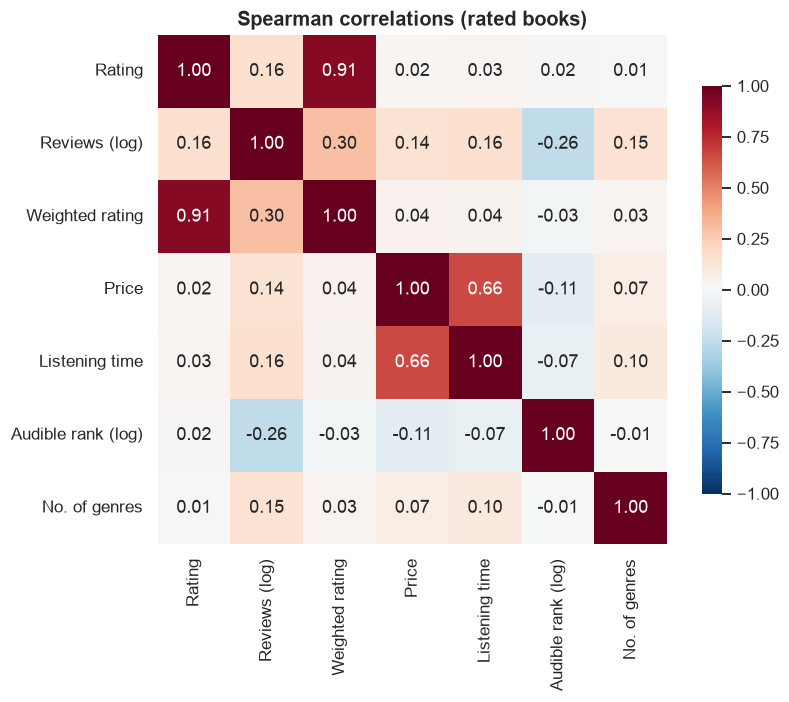

In [16]:
display(eda.correlation_table(books).round(2))
eda.chart_correlations(books);

**Findings.**
- **Price tracks listening time** (ρ = 0.66): audiobooks are priced by length, not by quality.
- Price and length are both **unrelated to rating** (ρ ≈ 0.02–0.03).
- A better Audible rank goes with more reviews (ρ = −0.26 with log rank) but not with a higher rating.
- Raw and weighted rating correlate at 0.91. They agree on most books and differ exactly where reviews are few.

### Price and listening time by genre

,median_price,median_hours,free_share
primary_genre,,,
Language & Education,₹569,3.6 h,25%
Children & Teens,₹615,4.9 h,1%
Religion & Spirituality,₹624,6.4 h,0%
Biographies & Memoirs,₹668,8.1 h,9%
Romance,₹668,8.7 h,6%
Personal Development,₹668,6.3 h,1%
Business & Careers,₹670,7.2 h,1%
Literature & Fiction,₹683,9.2 h,3%
Health & Wellness,₹683,7.4 h,5%


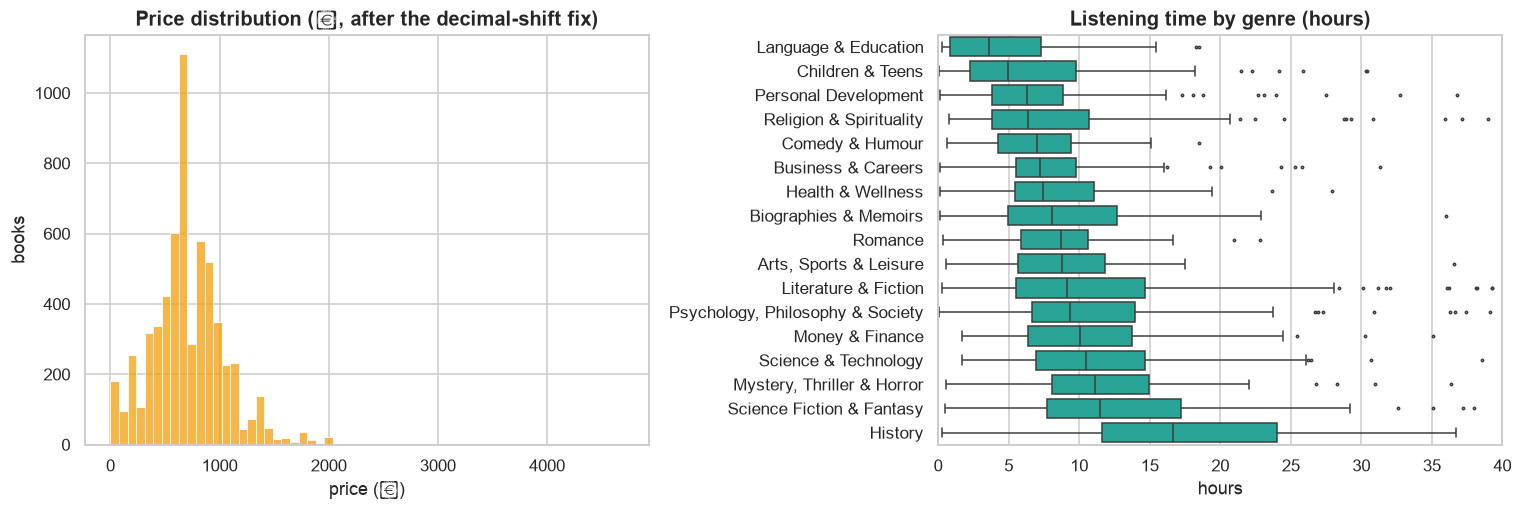

In [17]:
display(eda.price_and_length(books).style.format({"median_price": "₹{:,.0f}", "median_hours": "{:.1f} h", "free_share": "{:.0%}"}))
eda.chart_price_length(books);

**Findings.**
- **History** is the longest (median 16.7 h) and most expensive (₹1,003) genre. Sci-fi & fantasy (11.5 h, ₹888) and
  thrillers (11.2 h, ₹820) follow.
- **Language & Education** is the shortest and cheapest, and **25% of it is free** (taster lessons). That explains its
  tiny review counts and low ratings in Q1 and Q3.
- Children's titles are short (4.9 h) but among the highest rated. That makes them good value for a family-focused
  promotion.

## Summary
1. **Data quality is the main challenge.** About 2,000 descriptions were scrape failures, and 62% of books have no
   genre. The cleaning keeps those books for rating and author analysis, but never invents text or genres for them.
2. **Ratings are compressed** (mean 4.46, 61% at 4.5+). Weighted rating is essential, and raw 5.0s are mostly small
   samples.
3. **Popularity and quality are nearly independent.** That creates a real market for "hidden gem" recommendations.
4. **Recommendations:** description NLP alone recovers genre-mates at about 5× random. Adding genre and author blocks
   gives the best fair accuracy (precision@10 = 0.36). The hybrid model improves on pure content and recommends
   better-rated books.
5. **Clustering:** 16 interpretable clusters, confirmed independently by DBSCAN (ARI 0.98).
6. **Not answerable from this data:** publication-year trends (there is no date column). Joining publication dates in
   from an external books API is the next step.